# Medical Insurance Cost Prediction

**Goal:** predict a person's annual medical insurance charges from their age, sex, BMI, number of children, smoking status and region.

**Why it matters:** insurers price policies from expected cost. A model that explains *which* factors drive cost supports fairer pricing and targeted health programmes (for example, smoking cessation).

**Dataset:** [Medical Cost Personal Dataset (Kaggle)](https://www.kaggle.com/datasets/mirichoi0218/insurance): 1,338 rows, 7 columns.

**Workflow:** EDA → feature engineering → preprocessing pipeline → baseline → model comparison with 5-fold CV → hyperparameter tuning → final test evaluation → interpretation → saved model + prediction function.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from xgboost import XGBRegressor

# project helpers (src/features.py)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
from src.features import add_features, NUMERIC_FEATURES, CATEGORICAL_FEATURES, TARGET

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
DATA_PATH = ROOT / "data" / "insurance.csv"
IMG_DIR = ROOT / "images"
MODEL_DIR = ROOT / "models"
IMG_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

def save_fig(name):
    plt.savefig(IMG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")

## 2. Load data

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.924
1,18,male,33.770,1,no,southeast,1725.552
2,28,male,33.000,3,no,southeast,4449.462
3,33,male,22.705,0,no,northwest,21984.471
4,32,male,28.880,0,no,northwest,3866.855


| Column | Description | Type |
|---|---|---|
| age | Age of the primary beneficiary | Numeric |
| sex | female / male | Categorical |
| bmi | Body mass index (kg/m²) | Numeric |
| children | Number of dependents covered | Numeric (discrete) |
| smoker | yes / no | Categorical |
| region | US region: northeast, northwest, southeast, southwest | Categorical |
| **charges** | Annual medical cost billed by insurance (USD) | **Target** |

## 3. Data quality checks

In [3]:
df.info()
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1


In [4]:
# one exact duplicate row exists, so drop it to avoid leaking it across train/test
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)
df.describe().T

Shape after dropping duplicates: (1337, 7)


,count,mean,std,min,25%,50%,75%,max
age,1337.000,39.222,14.044,18.000,27.000,39.000,51.000,64.000
bmi,1337.000,30.663,6.100,15.960,26.290,30.400,34.700,53.130
children,1337.000,1.096,1.206,0.000,0.000,1.000,2.000,5.000
charges,1337.000,13279.121,12110.360,1121.874,4746.344,9386.161,16657.717,63770.428


In [5]:
for col in ["sex", "smoker", "region"]:
    print(df[col].value_counts(), "\n")

sex
male      675
female    662
Name: count, dtype: int64 

smoker
no     1063
yes     274
Name: count, dtype: int64 

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64 



**Observations:** no missing values and one duplicate (removed). Sex and region are balanced. Only about 20% of people are smokers.

## 4. Exploratory data analysis

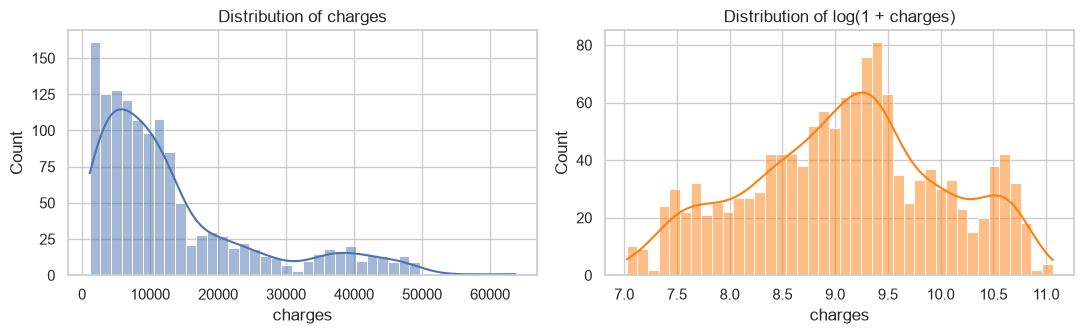

Skewness raw: 1.515 | log: -0.09


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df[TARGET], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of charges")
sns.histplot(np.log1p(df[TARGET]), bins=40, kde=True, ax=axes[1], color="tab:orange")
axes[1].set_title("Distribution of log(1 + charges)")
plt.tight_layout(); save_fig("target_distribution"); plt.show()
print("Skewness raw:", round(df[TARGET].skew(), 3), "| log:", round(np.log1p(df[TARGET]).skew(), 3))

**Charges are strongly right-skewed.** A log transform makes the distribution much more symmetric, and Section 8 tests whether modelling the log helps.

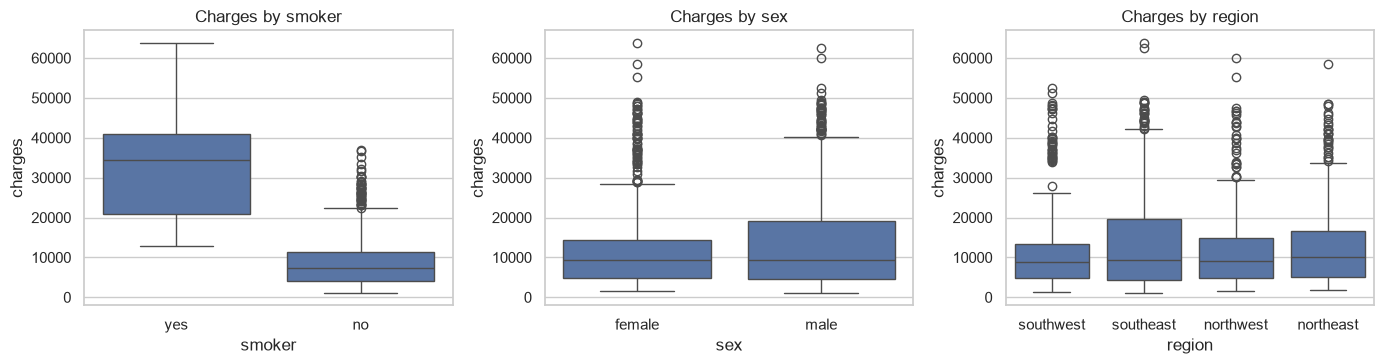

,count,mean,median
smoker,,,
no,1063,8440.660,7345.727
yes,274,32050.232,34456.348


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, ["smoker", "sex", "region"]):
    sns.boxplot(data=df, x=col, y=TARGET, ax=ax)
    ax.set_title(f"Charges by {col}")
plt.tight_layout(); save_fig("charges_by_category"); plt.show()

df.groupby("smoker")[TARGET].agg(["count", "mean", "median"])

**Smoking is the dominant factor.** Smokers pay roughly 3-4x more on average. Sex and region make little difference.

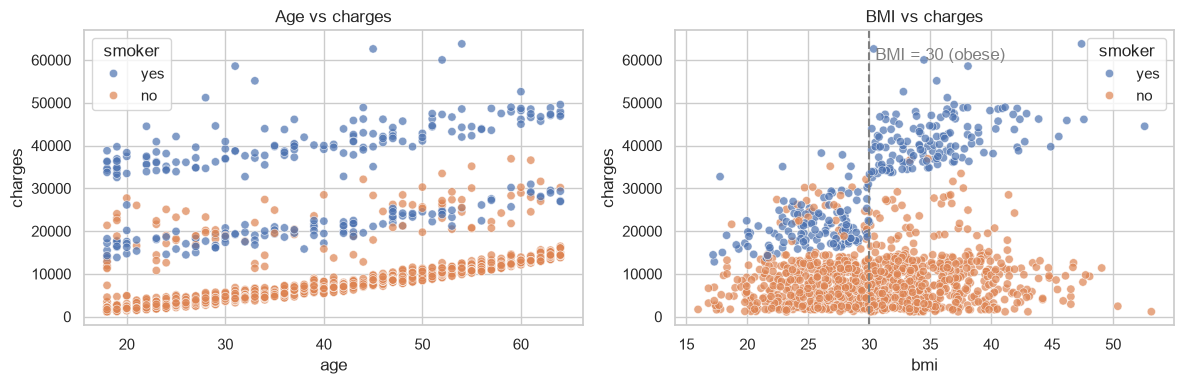

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x="age", y=TARGET, hue="smoker", alpha=0.7, ax=axes[0])
axes[0].set_title("Age vs charges")
sns.scatterplot(data=df, x="bmi", y=TARGET, hue="smoker", alpha=0.7, ax=axes[1])
axes[1].axvline(30, ls="--", c="grey"); axes[1].text(30.5, 60000, "BMI = 30 (obese)", color="grey")
axes[1].set_title("BMI vs charges")
plt.tight_layout(); save_fig("age_bmi_vs_charges"); plt.show()

**Key insight (interaction effect):**
- *Age vs charges* shows three bands: non-smokers (bottom), a middle band (mostly non-obese smokers) and a top band (obese smokers). Cost rises steadily with age in every band.
- *BMI vs charges*: for **non-smokers BMI barely matters**, but for **smokers there is a jump at BMI ≈ 30**. Obese smokers form the most expensive group.

So the effect of BMI *depends on* smoking status. A linear model cannot capture this unless we hand it an interaction feature, which motivates Section 5.

In [9]:
bmi_groups = df.assign(obese=df["bmi"] >= 30).groupby(["smoker", "obese"])[TARGET].mean().unstack()
bmi_groups.columns = ["BMI < 30", "BMI ≥ 30"]
bmi_groups

,BMI < 30,BMI ≥ 30
smoker,,
no,7977.030,8855.531
yes,21363.217,41557.990


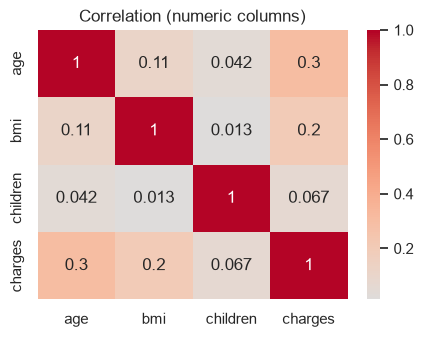

In [10]:
plt.figure(figsize=(5, 3.5))
sns.heatmap(df[["age", "bmi", "children", TARGET]].corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Correlation (numeric columns)"); plt.show()

## 5. Feature engineering

Based on the EDA, we add (see `src/features.py`):

| Feature | Definition | Reason |
|---|---|---|
| `bmi_smoker` | bmi × (smoker == yes) | BMI only drives cost for smokers |
| `age_smoker` | age × (smoker == yes) | Lets the age slope differ for smokers |
| `bmi_category` | WHO bands: underweight / normal / overweight / obese | Captures the threshold jump at BMI 30 |

In [11]:
df_fe = add_features(df)
df_fe.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category,bmi_smoker,age_smoker
0,19,female,27.900,0,yes,southwest,16884.924,overweight,27.900,19
1,18,male,33.770,1,no,southeast,1725.552,obese,0.000,0
2,28,male,33.000,3,no,southeast,4449.462,obese,0.000,0
3,33,male,22.705,0,no,northwest,21984.471,normal,0.000,0
4,32,male,28.880,0,no,northwest,3866.855,overweight,0.000,0


## 6. Train/test split and preprocessing pipeline

In [12]:
BASE_NUM = ["age", "bmi", "children"]
BASE_CAT = ["sex", "smoker", "region"]

X = df_fe.drop(columns=[TARGET])
y = df_fe[TARGET]

# stratify on smoker so both sets have the same share of the most important group
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=X["smoker"]
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

def make_preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
    ])

pre_base = make_preprocessor(BASE_NUM, BASE_CAT)
pre_fe = make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES)

Train: (1069, 9) | Test: (268, 9)


All preprocessing lives **inside** the pipeline, so scaling and encoding are learned from the training folds only. This avoids data leakage during cross-validation.

## 7. Baseline and model comparison (5-fold CV)

In [13]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}

models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=10000, random_state=RANDOM_STATE),
    "DecisionTree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "RandomForest": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1),
}

rows = []
for feat_name, pre in [("base", pre_base), ("engineered", pre_fe)]:
    for name, model in models.items():
        pipe = Pipeline([("preprocess", pre), ("model", model)])
        s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
        rows.append({"features": feat_name, "model": name,
                     "cv_mae": -s["test_mae"].mean(),
                     "cv_rmse": -s["test_rmse"].mean(),
                     "cv_r2": s["test_r2"].mean()})

cv_results = pd.DataFrame(rows).sort_values("cv_mae").reset_index(drop=True)
cv_results

,features,model,cv_mae,cv_rmse,cv_r2
0,engineered,GradientBoosting,2774.526,4833.954,0.834
1,base,GradientBoosting,2803.234,4843.471,0.833
2,base,RandomForest,2845.591,5004.108,0.820
3,engineered,RandomForest,2878.657,5015.518,0.819
4,engineered,Lasso,3065.847,4994.267,0.823
5,engineered,LinearRegression,3067.306,4995.451,0.823
6,engineered,Ridge,3077.436,5002.784,0.823
7,engineered,XGBoost,3245.277,5440.261,0.788
8,engineered,DecisionTree,3245.997,6693.444,0.671
9,base,DecisionTree,3266.563,6689.323,0.669


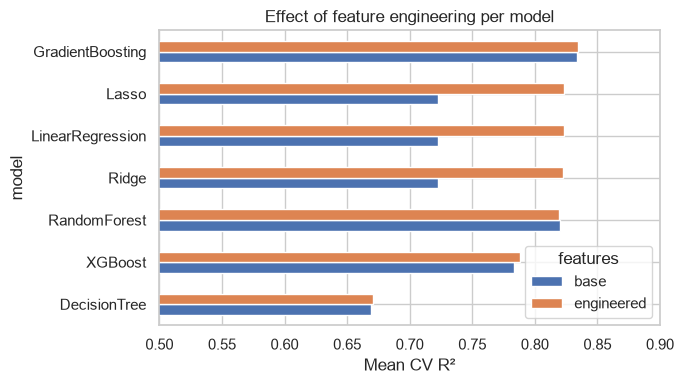

In [14]:
pivot = cv_results.pivot(index="model", columns="features", values="cv_r2").sort_values("engineered")
pivot.plot.barh(figsize=(7, 4))
plt.xlabel("Mean CV R²"); plt.title("Effect of feature engineering per model")
plt.xlim(0.5, 0.9); plt.tight_layout(); save_fig("feature_engineering_effect"); plt.show()

**Observations:**
- The interaction features have the biggest effect on **linear models**. They let a simple, interpretable model capture the smoker × BMI effect.
- Tree ensembles find the interactions on their own, so they gain less, but they still lead overall.

## 8. Hyperparameter tuning

We tune Gradient Boosting (a top CV performer) and also test a **log-transformed target**, since charges are heavily skewed. `GridSearchCV(refit=True)` gives us `best_estimator_` directly, so the final model uses exactly the parameters the search found.

In [15]:
gb_pipe = Pipeline([
    ("preprocess", pre_fe),
    ("model", GradientBoostingRegressor(random_state=RANDOM_STATE)),
])
param_grid = {
    "model__n_estimators": [100, 200, 400],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__min_samples_leaf": [5, 10, 20],
    "model__subsample": [0.8, 1.0],
}
grid = GridSearchCV(gb_pipe, param_grid, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1, refit=True)
grid.fit(X_train, y_train)
print("Best CV MAE:", round(-grid.best_score_, 2))
print("Best params:", grid.best_params_)

Best CV MAE: 2697.61
Best params: {'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__min_samples_leaf': 10, 'model__n_estimators': 200, 'model__subsample': 0.8}


In [16]:
# same search, but model log(1 + charges) and convert predictions back
log_pipe = TransformedTargetRegressor(regressor=gb_pipe, func=np.log1p, inverse_func=np.expm1)
log_grid = GridSearchCV(
    log_pipe,
    {f"regressor__{k}": v for k, v in param_grid.items()},
    cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1, refit=True,
)
log_grid.fit(X_train, y_train)
print("Best CV MAE (log target):", round(-log_grid.best_score_, 2))
print("Best params:", log_grid.best_params_)

Best CV MAE (log target): 2228.63
Best params: {'regressor__model__learning_rate': 0.05, 'regressor__model__max_depth': 4, 'regressor__model__min_samples_leaf': 5, 'regressor__model__n_estimators': 100, 'regressor__model__subsample': 1.0}


In [17]:
candidates = {"GB (raw target)": grid, "GB (log target)": log_grid}
best_name = min(candidates, key=lambda k: -candidates[k].best_score_)
final_model = candidates[best_name].best_estimator_
print("Selected final model:", best_name)

Selected final model: GB (log target)


## 9. Final evaluation on the held-out test set

In [18]:
def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": root_mean_squared_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}

baseline = Pipeline([("preprocess", pre_base), ("model", LinearRegression())]).fit(X_train, y_train)

results = pd.DataFrame({
    "Baseline LR (train)": metrics(y_train, baseline.predict(X_train)),
    "Baseline LR (test)": metrics(y_test, baseline.predict(X_test)),
    f"{best_name} (train)": metrics(y_train, final_model.predict(X_train)),
    f"{best_name} (test)": metrics(y_test, final_model.predict(X_test)),
}).T
results

,MAE,RMSE,R2
Baseline LR (train),4340.912,6266.165,0.733
Baseline LR (test),3592.793,5086.880,0.820
GB (log target) (train),1926.433,4316.282,0.873
GB (log target) (test),1600.921,3302.727,0.924


The test set was not touched during model selection or tuning, so the test row is an honest estimate of real-world performance. A small train/test gap means the model is not overfitting.

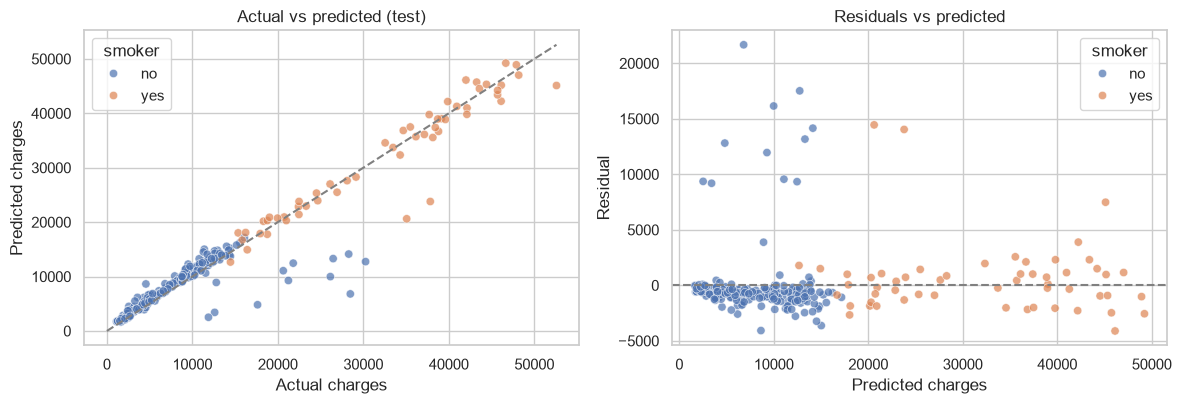

In [19]:
test_pred = final_model.predict(X_test)
residuals = y_test - test_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.scatterplot(x=y_test, y=test_pred, hue=X_test["smoker"], alpha=0.7, ax=axes[0])
lims = [0, max(y_test.max(), test_pred.max())]
axes[0].plot(lims, lims, "--", c="grey")
axes[0].set_xlabel("Actual charges"); axes[0].set_ylabel("Predicted charges"); axes[0].set_title("Actual vs predicted (test)")
sns.scatterplot(x=test_pred, y=residuals, hue=X_test["smoker"], alpha=0.7, ax=axes[1])
axes[1].axhline(0, c="grey", ls="--")
axes[1].set_xlabel("Predicted charges"); axes[1].set_ylabel("Residual"); axes[1].set_title("Residuals vs predicted")
plt.tight_layout(); save_fig("actual_vs_predicted"); plt.show()

In [20]:
# where does the model struggle?
err = pd.DataFrame({"smoker": X_test["smoker"], "abs_error": residuals.abs()})
err.groupby("smoker")["abs_error"].describe()[["count", "mean", "50%", "max"]]

,count,mean,50%,max
smoker,,,,
no,213.000,1509.112,753.008,21666.647
yes,55.000,1956.472,1153.453,14452.563


Most points sit on the diagonal. The large residuals are a few people whose charges sit far above what their profile suggests. These are probably caused by medical conditions this dataset doesn't record.

## 10. Model interpretation: permutation importance

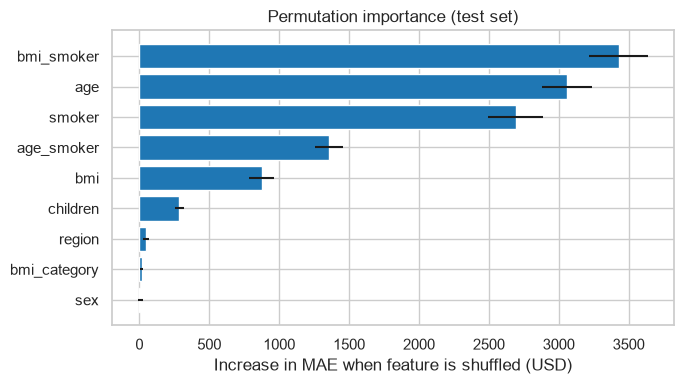

,feature,importance,std
7,bmi_smoker,3428.225,213.263
0,age,3059.090,179.539
4,smoker,2691.750,197.919
8,age_smoker,1358.511,100.248
2,bmi,875.523,88.844
3,children,286.396,32.102
5,region,49.081,20.458
6,bmi_category,15.402,8.397
1,sex,7.210,18.936


In [21]:
perm = permutation_importance(final_model, X_test, y_test, n_repeats=20,
                              random_state=RANDOM_STATE, scoring="neg_mean_absolute_error")
importance = (pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean,
                            "std": perm.importances_std})
              .sort_values("importance", ascending=True))

plt.figure(figsize=(7, 4))
plt.barh(importance["feature"], importance["importance"], xerr=importance["std"], color="tab:blue")
plt.xlabel("Increase in MAE when feature is shuffled (USD)")
plt.title("Permutation importance (test set)")
plt.tight_layout(); save_fig("feature_importance"); plt.show()
importance.sort_values("importance", ascending=False)

Permutation importance measures how much the test error grows when one column is randomly shuffled. Unlike tree-based importance, it works for any model and is measured on unseen data.

## 11. Save the model and build a prediction function

In [22]:
joblib.dump(final_model, MODEL_DIR / "insurance_model.joblib")
print("Saved to models/insurance_model.joblib")

def predict_insurance_charges(age, sex, bmi, children, smoker, region, model=final_model):
    row = pd.DataFrame([{"age": age, "sex": sex, "bmi": bmi, "children": children,
                         "smoker": smoker, "region": region}])
    return float(model.predict(add_features(row))[0])

examples = [
    dict(age=35, sex="male", bmi=29.5, children=2, smoker="no", region="southeast"),
    dict(age=35, sex="male", bmi=29.5, children=2, smoker="yes", region="southeast"),
    dict(age=35, sex="male", bmi=33.0, children=2, smoker="yes", region="southeast"),
]
for e in examples:
    print(f"{e['smoker']:>3} smoker, BMI {e['bmi']}: predicted charges = ${predict_insurance_charges(**e):,.2f}")

Saved to models/insurance_model.joblib
 no smoker, BMI 29.5: predicted charges = $6,379.93
yes smoker, BMI 29.5: predicted charges = $20,872.68
yes smoker, BMI 33.0: predicted charges = $38,613.69


## 12. Conclusions

**Results (held-out test set, 268 people)**

| Model | MAE (USD) | RMSE (USD) | R² |
|---|---|---|---|
| Baseline: Linear Regression, raw features | ≈ 3,590 | ≈ 5,090 | 0.82 |
| **Final: tuned Gradient Boosting, engineered features, log target** | **≈ 1,600** | **≈ 3,300** | **0.92** |

The final model cuts the average prediction error by about **55%** compared with the baseline.

**What we learned**
1. **Smoking dominates cost.** Smokers average about $32k a year, against about $8.4k for non-smokers.
2. **BMI matters only for smokers.** Obese smokers (BMI ≥ 30) average about $41.6k, nearly double non-obese smokers (about $21.4k). For non-smokers, obesity adds less than $1k.
3. **Domain-driven feature engineering pays off.** The `bmi_smoker` interaction became the single most important feature. It raised linear regression's CV R² from 0.72 to 0.82, so a simple, explainable model can almost match tree ensembles.
4. **Log-transforming the skewed target** lowered the tuned model's CV MAE from about $2,700 to about $2,230.
5. Sex and region have almost no predictive value.

**Limitations**
- Small dataset (1,337 rows) from one source. The test R² (0.92) is higher than the training R² (0.87), which means this particular split happens to be easy. The 5-fold cross-validated scores in Section 7 (R² ≈ 0.83 for Gradient Boosting) are the more conservative estimate.
- No medical history, so some very high-cost cases can't be explained and produce large errors.
- The model learns historical pricing. Any use in real pricing would need a fairness review.

**Future work:** prediction intervals (quantile regression), SHAP values for per-person explanations, and a small web app (Streamlit) built on `src/predict.py`.